# A Modified SEIR Model for the Spread of Ebola in Western Africa and Metrics for Resource Allocation

__Paul Diaz__, Department of Aerospace Engineering Sciences, University of Colorado, Boulder

__Paul Constantine__, Department of Computer Science, University of Colorado, Boulder

__Kelsey Kalmbach__, Department of Applied Mathematics and Statistics, Colorado School of Mines

__Eric Jones__, Department of Physics, University of California at Santa Barbara

__Stephen Pankavich__, Department of Applied Mathematics and Statistics, Colorado School of Mines

__Ryan Howard__ (2016 notebook)

<br>

In this notebook, we'll be summarizing the active subspaces-based global sensitivity analysis on a model for the spread of Ebola, presented in [[1]][R1]. The affiliations are those of the published paper. The analysis uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`). It takes about 20 seconds and needs about 400 MB of memory.

### Introduction

The recent Ebola outbreak in Western Africa has been the deadliest Ebola outbreak to date and has drawn international attention and support to the region. Important questions to consider are which countries should receive additional aid and what aspects of the outbreak should the aid address. Some distinct characteristics of Ebola are its ability to remain infectious after the death of a host (especially problematic considering local burial rituals involve ample contact with the bodies of the dead) and the effects of hospitalization (hospital workers can be infected through contact with patients). In this notebook, we discuss an SEIR model that accounts for these aspects of Ebola and use _active subspaces_ to explore the global sensitivity of the model to its parameters.

### The Ebola Model

The model we employ is a modified SEIR model with the following assumptions: stochastic effects are negligible; births and non-ebola deaths are negligible; an individual can be removed and infectious (not properly buried), removed and non-infectious (properly buried), or removed and recovered; recovered individuals do not turn susceptible again; hospitalized individuals can spread the disease; deaths in hospitals are properly buried; and hospitalization increases chances of recovery. Under these assumptions, the equations governing our model are ([[1]][R1], Eqs. (1)–(2)):

$$
\begin{align}
\frac{dS}{dt} &= -\beta_1SI - \beta_2SR_I - \beta_3SH,\\
\frac{dE}{dt} &= \beta_1SI + \beta_2SR_I + \beta_3SH - \delta E,\\
\frac{dI}{dt} &= \delta E - \gamma_1I - \psi I,\\
\frac{dH}{dt} &= \psi I - \gamma_2H,\\
\frac{dR_I}{dt} &= \rho_1\gamma_1I - \omega R_I,\\
\frac{dR_B}{dt} &= \omega R_I + \rho_2\gamma_2H,\\
\frac{dR_R}{dt} &= (1-\rho_1)\gamma_1I + (1-\rho_2)\gamma_2H,
\end{align}
$$

where $S$ represents the fraction of the population that is susceptible to infection, $E$ is the exposed population (infected but asymptomatic), $I$ is the infected fraction, $H$ is the hospitalized fraction, $R_I$ is the infectious dead (not properly buried), $R_B$ is the non-infectious dead (properly buried), and $R_R$ is the recovered population.

The basic reproduction number (a metric measuring how many new cases of disease each current case causes) can be found to be ([[1]][R1], Eq. (4))

$$
R_0 = \frac{\beta_1 + \frac{\beta_2\rho_1\gamma_1}{\omega} + \frac{\beta_3}{\gamma_2}\psi}{\gamma_1 + \psi}.
$$

It depends on eight of the parameters; $\delta$ and $\rho_2$ do not enter it. The parameters are fit using data for the countries of Liberia and Sierra Leone, the results of which are summarized in the table below ([[1]][R1], Table 2; $\delta$ is assumed to be $\frac 1 9$ in each case, a number taken from other sources). [[1]][R1] also fits Guinea, but leaves it out of the active subspace analysis, and so do we.

Parameter | Liberia | Sierra Leone
:--------:|:-------:|:---------:
$\beta_1$|.376|.251
$\beta_2$|.135|.395
$\beta_3$|.163|.079
$\gamma_1$|.0542|.051
$\gamma_2$|.174|.0833
$\psi$|.5|.442
$\rho_1$|.98|.76
$\rho_2$|.88|.74
$\omega$|.325|.370

[[1]][R1] (Table 3) reports basic reproduction numbers of 1.563 for Liberia and 1.445 for Sierra Leone. From the rounded values in the table, $R_0$ is 1.5634 for Liberia and 1.4433 for Sierra Leone (printed below). The Sierra Leone difference is rounding: with the less-rounded fit in [[1]][R1], Fig. 2c ($\beta_3 = .0791$, $\gamma_1 = .0510$, $\rho_1 = .766$), $R_0$ is 1.4451.

### Active Subspaces

Active subspaces is a method for quantifying the global sensitivity of a model's output to its input parameters. In our case, the output is $R_0(\mathbf x)$, where $\mathbf x\in [-1,1]^8$ is a vector representing the 8 normalized parameters $R_0$ depends on. The method is based on the matrix

$$
\mathbf C = \int\nabla R_0(\mathbf x)\nabla R_0(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\nabla R_0$ is the gradient of $R_0$ with respect to the normalized parameters, $\rho$ is a probability density on the parameters, and $\mathbf W\Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$ (with the eigenvalues in descending order). The eigenpairs satisfy the relationship $\lambda_i = \int(\nabla R_0^T\mathbf w_i)^2\rho\ d\mathbf x$. In words, this means the $i^{th}$ eigenvalue quantifies the average squared derivative of $R_0$ in the direction defined by the corresponding eigenvector; if some eigenvalues are small compared to the rest, $R_0$ will likely be relatively flat in the subspace defined by the span of the corresponding eigenvectors. Suppose $\lambda_{n+1} \ll \lambda_n$ for some $n < 8$. Then we can partition the eigendecomposition as

$$
\Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],\ \mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],
$$

where $\Lambda_1$ contains the first $n$ eigenvalues and $\mathbf W_1$ the corresponding eigenvectors. We define $\alpha\in R^8$ as $\alpha = \alpha(n) = \sum_{j=1}^n\lambda_j\mathbf w_j^2$, where the exponent is elementwise. We call the components of $\alpha$ _activity scores_; a larger score for a parameter indicates relative sensitivity compared to the others.

For the following analysis, we use the following distributions ($\rho = $ U(min, max)) for the parameters ([[1]][R1], Table 7).

Parameter | Liberia | Sierra Leone
:--------:|:-------:|:---------:
$\beta_1$|U(.1, .4)|U(.1, .4)
$\beta_2$|U(.1, .4)|U(.1, .4)
$\beta_3$|U(.05, .2)|U(.05, .2)
$\rho_1$|U(.41, 1)|U(.41, 1)
$\gamma_1$|U(.0276, .1702)|U(.0275, .1569)
$\gamma_2$|U(.081, .21)|U(.1236, .384)$^*$
$\omega$|U(.25, .5)|U(.25, .5)
$\psi$|U(.0833, .7)|U(.0833, .7)

$^*$ The fitted Sierra Leone value $\gamma_2 = .0833$ ([[1]][R1], Table 2) lies outside this range, U(.1236, .384) ([[1]][R1], Table 7). The two disagree in the published paper, and it is not known which value is wrong. The analysis below uses the range as published.

### References:

[[1]][R1] P. Diaz, P. Constantine, K. Kalmbach, E. Jones, and S. Pankavich. _A modified SEIR model for the spread of Ebola in Western Africa and metrics for resource allocation_. Appl. Math. Comput., 324:141–155, 2018. doi:10.1016/j.amc.2017.11.039 ([arXiv:1603.04955][R1a])

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[R1]: https://doi.org/10.1016/j.amc.2017.11.039
[R1a]: https://arxiv.org/abs/1603.04955
[R2]: https://doi.org/10.1137/130916138

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

<br>

We'll now code up the analysis using the [active_subspaces](https://github.com/paulcon/active_subspaces) library.

In [1]:
%matplotlib inline
import resource
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import roots_legendre
import active_subspaces as ac
from ebola_model import R0, R0_grad, NAMES, LABELS, COUNTRIES, FITTED, BOUNDS

t_start = time.perf_counter()
rng = np.random.default_rng(2018)        # the only source of randomness in this notebook


def peak_rss_gb():
    """Peak resident memory of this process so far, in GB."""
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return r / 1e9 if sys.platform == 'darwin' else r * 1024 / 1e9   # bytes on macOS, KiB on Linux


spaces = {c: ac.Uniform(lower=BOUNDS[c][0], upper=BOUNDS[c][1], names=NAMES) for c in COUNTRIES}

$R_0$ and its gradient with respect to the physical (unnormalized) parameters are in `ebola_model.py`, next to this notebook. First we evaluate $R_0$ at the fitted values, and check the gradient against central finite differences at a random point in each country's parameter box.

In [2]:
for c in COUNTRIES:
    print(f'{c}: R0 at the Table 2 values = {R0(FITTED[c]):.4f}')
fig2c = FITTED['Sierra Leone'].copy()
fig2c[[2, 3, 4]] = .0791, .766, .0510     # beta3, rho1, gamma1 as printed in Fig. 2c
print(f'Sierra Leone: R0 at the Fig. 2c values = {R0(fig2c):.4f}')

h = 1e-6
for c in COUNTRIES:
    x = spaces[c].sample(1, rng=rng)[0]
    g = R0_grad(x)
    fd = np.array([(R0(x + h*e) - R0(x - h*e)) / (2*h) for e in np.eye(8)])
    print(f'{c}: max relative error of the gradient vs finite differences = '
          f'{np.max(np.abs(fd - g) / np.abs(g)):.1e}')

Liberia: R0 at the Table 2 values = 1.5634
Sierra Leone: R0 at the Table 2 values = 1.4433
Sierra Leone: R0 at the Fig. 2c values = 1.4451
Liberia: max relative error of the gradient vs finite differences = 2.4e-09
Sierra Leone: max relative error of the gradient vs finite differences = 2.2e-10


$\mathbf C$ is approximated with a tensor-product Gauss-Legendre rule with 8 points in each of the 8 dimensions of the parameter space, $8^8 = 16{,}777{,}216$ points, as in [[1]][R1]. The one-dimensional weights are halved so that they sum to 1 on $[-1, 1]$, and so the tensor weights already include the uniform density $\rho(\mathbf x) = 2^{-8}$. The 2016 version of this notebook multiplied by $2^{-8}$ a second time, which made every eigenvalue 256 times too small; its eigenvalue plots show $\lambda_1 \approx 4\times 10^{-3}$ for Liberia instead of about 1. The eigenvectors and the normalized activity scores do not depend on that factor.

Gradients with respect to normalized parameters follow from the chain rule: if $p$ is an unnormalized parameter and $x$ is its normalized version, then $\frac{\partial R_0}{\partial x} = \frac{\partial R_0}{\partial p}\frac{\partial p}{\partial x}$, and $p = l + \frac{u-l}{2}(x+1)\Rightarrow\frac{\partial p}{\partial x} = \frac{u - l}{2}$, where $u$ and $l$ are the upper and lower bounds on the parameter. The physical gradients are multiplied by this scaling, `space.scale`, the diagonal matrix with entries $\frac{u-l}{2}$.

The full gradient array would hold $16{,}777{,}216\times 8$ numbers (1.07 GB), and `ac.active_subspace` would copy it. Instead we accumulate $\mathbf C = \sum_i \omega_i \nabla R_0(\mathbf x_i)\nabla R_0(\mathbf x_i)^T$ in 64 blocks of $8^6$ points and pass the $8\times 8$ matrix to `ac.subspace_from_matrix`, which returns the same kind of result as `ac.active_subspace`. Each country takes about 7 seconds, and the peak memory of the notebook is about 400 MB (printed at the end). First we check, on the smaller $5^8$ rule, that the blocked matrix gives the same eigenpairs as `ac.active_subspace` with the full gradient array and the quadrature weights.

In [3]:
def tensor_rule_C(space, k):
    # C = sum_i w_i g_i g_i^T over the k^8 tensor Gauss-Legendre rule, in normalized coordinates.
    # The points are visited in k^2 blocks of k^6 points (the first two coordinates fixed per
    # block), so the full gradient array is never held in memory.
    t, w = roots_legendre(k)
    w = w / 2                                                                  # sum to 1 on [-1, 1]
    T6 = np.stack(np.meshgrid(*[t]*6, indexing='ij'), axis=-1).reshape(-1, 6)  # last 6 coordinates
    W6 = np.prod(np.stack(np.meshgrid(*[w]*6, indexing='ij'), axis=-1).reshape(-1, 6), axis=1)
    scale = np.diag(space.scale)                                               # (u - l)/2
    C, wsum = np.zeros((8, 8)), 0.
    for a in range(k):
        for b in range(k):
            Tn = np.hstack([np.full((len(T6), 1), t[a]), np.full((len(T6), 1), t[b]), T6])
            wb = w[a] * w[b] * W6
            Gs = R0_grad(space.from_normalized(Tn)) * scale * np.sqrt(wb)[:, None]   # chain rule
            C += Gs.T @ Gs
            wsum += wb.sum()
    return C, wsum


def oriented(s):
    # v1 makes each eigenvector's largest component positive. The 2016 package made the
    # first component positive, as in the figures of [1]; restore that rule for w1 and w2.
    return ac.orient(s, by='reference', reference=np.eye(8)[:, [0, 0]], columns=2)


# Check on the 5^8 rule (390,625 points): blocked C vs the full gradient array.
t5, w5 = roots_legendre(5)
T5 = np.stack(np.meshgrid(*[t5]*8, indexing='ij'), axis=-1).reshape(-1, 8)
W5 = np.prod(np.stack(np.meshgrid(*[w5 / 2]*8, indexing='ij'), axis=-1).reshape(-1, 8), axis=1)
for c in COUNTRIES:
    full = oriented(ac.active_subspace(space=spaces[c], grads=R0_grad(spaces[c].from_normalized(T5)),
                                       quad_weights=W5, n=2, qoi='R0'))
    blocked = oriented(ac.subspace_from_matrix(tensor_rule_C(spaces[c], 5)[0], space=spaces[c], n=2, qoi='R0'))
    print(f'{c}, 5^8 rule: max relative eigenvalue difference '
          f'{np.max(np.abs(blocked.eigenvalues / full.eigenvalues - 1)):.1e}, '
          f'max |w1, w2 difference| {np.abs(blocked.W[:, :2] - full.W[:, :2]).max():.1e}')
del T5, W5

sub = {}
for c in COUNTRIES:
    t0 = time.perf_counter()
    C, wsum = tensor_rule_C(spaces[c], 8)
    sub[c] = oriented(ac.subspace_from_matrix(C, space=spaces[c], n=2, qoi='R0'))
    print(f'{c}, 8^8 rule ({8**8:,} points, |1 - weight sum| = {abs(1 - wsum):.0e}): '
          f'{time.perf_counter() - t0:.1f} s, peak memory so far {peak_rss_gb()*1e3:.0f} MB')

Liberia, 5^8 rule: max relative eigenvalue difference 1.7e-13, max |w1, w2 difference| 1.8e-15


Sierra Leone, 5^8 rule: max relative eigenvalue difference 6.2e-14, max |w1, w2 difference| 6.1e-16


Liberia, 8^8 rule (16,777,216 points, |1 - weight sum| = 2e-16): 6.8 s, peak memory so far 412 MB


Sierra Leone, 8^8 rule (16,777,216 points, |1 - weight sum| = 2e-16): 6.3 s, peak memory so far 422 MB


We print the eigenvalues, and the values the 2016 notebook plotted ($2^{-8}$ times ours).

In [4]:
for c in COUNTRIES:
    lam = sub[c].eigenvalues
    print(f'{c}:')
    print('  eigenvalues        ', np.array2string(lam, precision=4, max_line_width=200))
    print(f'  lambda1/lambda2 = {lam[0]/lam[1]:.1f}, lambda3/lambda1 = {lam[2]/lam[0]:.3f}, '
          f'lambda8/lambda1 = {lam[7]/lam[0]:.1e}')
    print('  2016 plot (x 2^-8) ', np.array2string(lam[:3] * 2.**-8, precision=2))

Liberia:
  eigenvalues         [1.0217e+00 2.6304e-01 2.5141e-02 1.3045e-02 4.3808e-03 1.4168e-03 3.6834e-04 7.8103e-05]
  lambda1/lambda2 = 3.9, lambda3/lambda1 = 0.025, lambda8/lambda1 = 7.6e-05
  2016 plot (x 2^-8)  [3.99e-03 1.03e-03 9.82e-05]
Sierra Leone:
  eigenvalues         [1.1049e+00 1.5506e-01 2.1797e-02 5.4417e-03 3.5037e-03 1.1001e-03 3.1874e-04 6.1777e-05]
  lambda1/lambda2 = 7.1, lambda3/lambda1 = 0.020, lambda8/lambda1 = 5.6e-05
  2016 plot (x 2^-8)  [4.32e-03 6.06e-04 8.51e-05]


We'll now plot various quantities related to the active subspace analysis, starting with eigenvalues.

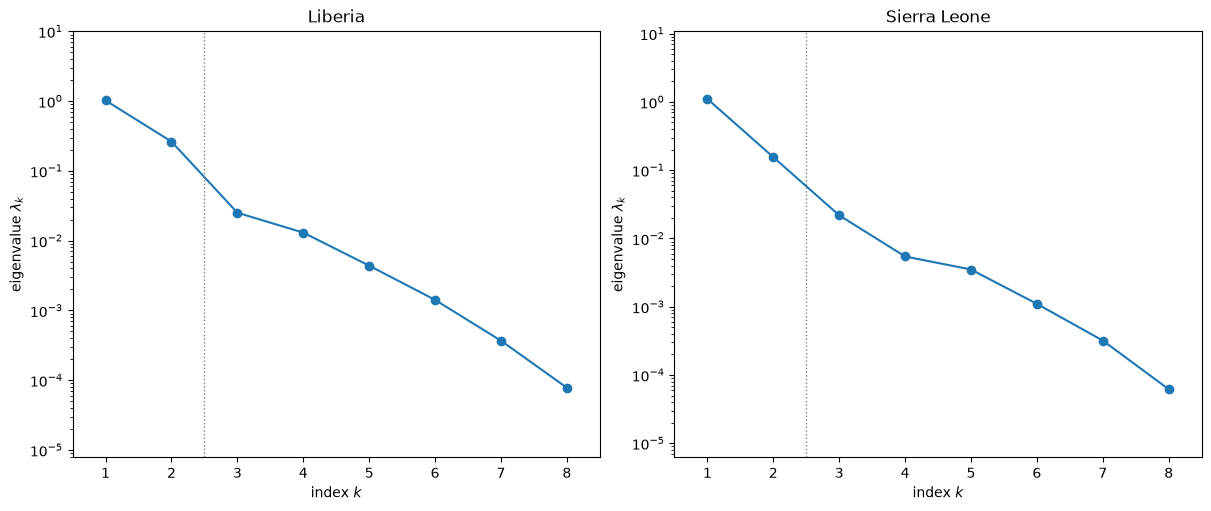

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, c in zip(axes, COUNTRIES):
    ac.plotting.plot_eigenvalues(sub[c], ax=ax)
    ax.set_title(c)
plt.show()

We can see for both countries that the last 6 eigenvalues are at least an order of magnitude smaller than the first eigenvalue ($\lambda_3/\lambda_1$ is 0.025 for Liberia and 0.020 for Sierra Leone); based on this, we might expect a reasonably good 2-dimensional subspace. To visualize the quality of the subspaces, we make sufficient summary plots, showing the model output, $R_0$, against the first 1 or 2 active variables ($\mathbf w_1^T\mathbf x$ and $\mathbf w_2^T\mathbf x$), at 2000 points drawn uniformly at random from each country's parameter box.

Liberia: correlation of R0 with the first active variable = 0.855
Sierra Leone: correlation of R0 with the first active variable = 0.843


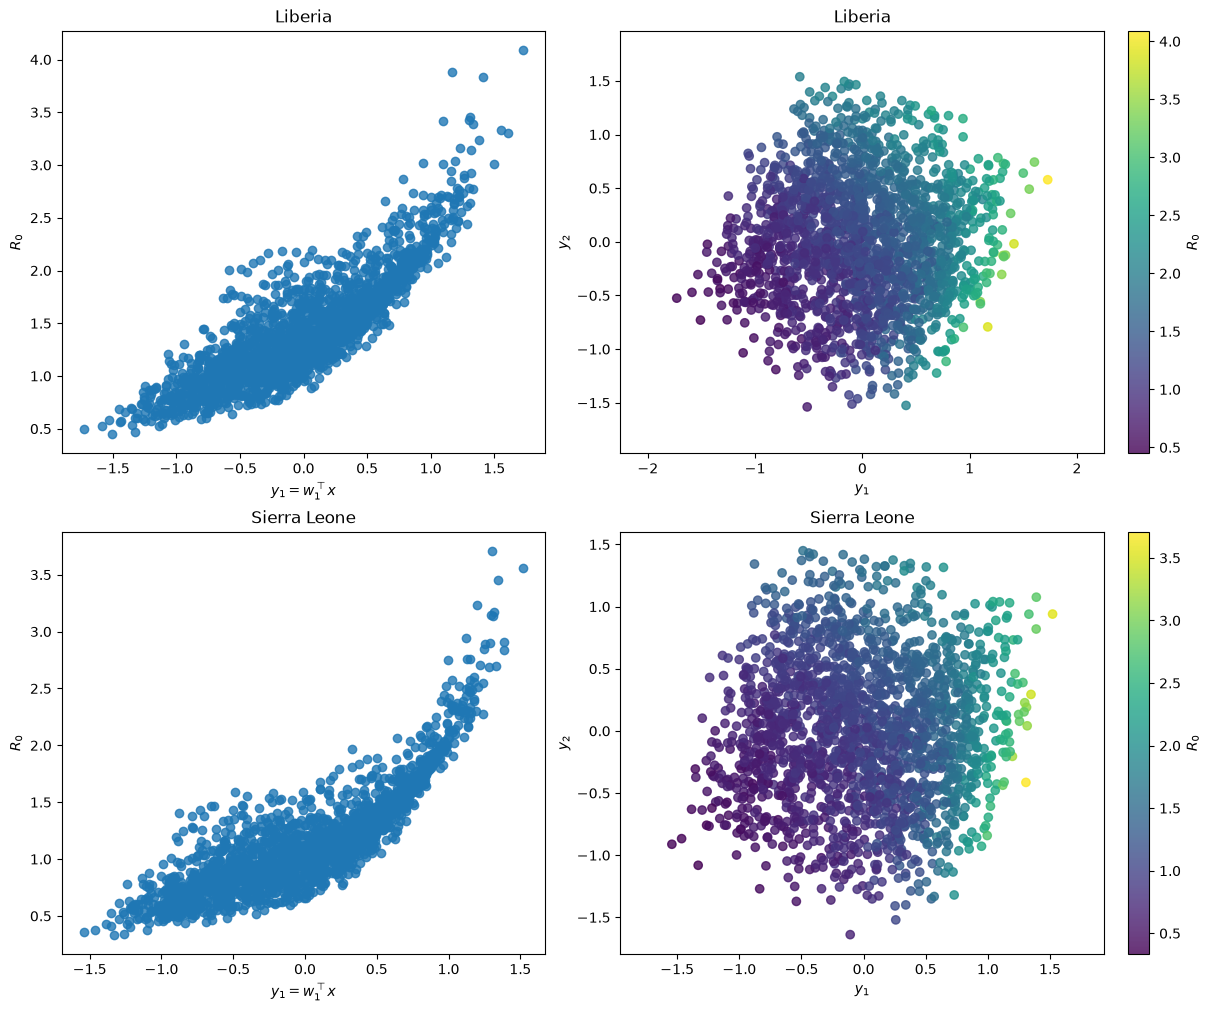

In [6]:
Xn = rng.uniform(-1, 1, (2000, 8))        # normalized points, mapped into each country's box
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout='constrained')
for row, c in zip(axes, COUNTRIES):
    X = spaces[c].from_normalized(Xn)
    for ax, dims in zip(row, (1, 2)):
        ac.plotting.plot_sufficient_summary(sub[c], X=X, f=R0(X), dims=dims, qoi_label=r'$R_0$', ax=ax)
        ax.set_title(c)
    y1 = spaces[c].to_normalized(X) @ sub[c].W[:, 0]
    print(f'{c}: correlation of R0 with the first active variable = {np.corrcoef(y1, R0(X))[0, 1]:.3f}')
plt.show()

We see fairly tight trends in the 1-dimensional plots, but the trends are much tighter in the 2-dimensional plots, as we would expect based on the eigenvalues. The tight trends indicate good subspace quality, so we can reasonably make conclusions regarding the global sensitivity of output using the 2-dimensional subspace.

One way to use active subspaces to quantify sensitivity is through eigenvector components; higher-magnitude components in the first few eigenvectors indicate relative sensitivity to the corresponding parameters. We plot the components of the first eigenvector for each country now. With the sign rule above, $R_0$ increases along $\mathbf w_1$ on average, so a negative component means that increasing the parameter decreases $R_0$.

Liberia: w1 = beta1 +0.381, beta2 +0.061, beta3 +0.336, rho1 +0.043, gamma1 -0.255, gamma2 -0.298, omega -0.037, psi -0.762
Sierra Leone: w1 = beta1 +0.364, beta2 +0.055, beta3 +0.166, rho1 +0.039, gamma1 -0.190, gamma2 -0.177, omega -0.034, psi -0.876


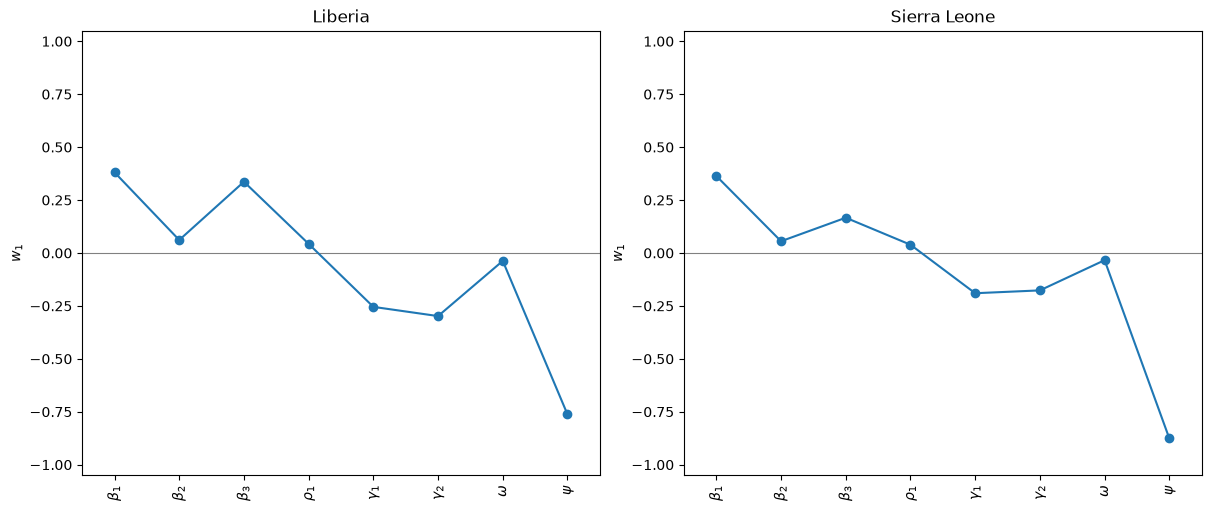

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, c in zip(axes, COUNTRIES):
    ac.plotting.plot_eigenvectors(sub[c], indices=[0], labels=LABELS, ax=ax)
    ax.set_title(c)
    print(f'{c}: w1 =', ', '.join(f'{n} {v:+.3f}' for n, v in zip(NAMES, sub[c].W[:, 0])))
plt.show()

We can see that in each country, $\psi$ (representing the hospitalization rate) is the most important parameter and several parameters (especially $\beta_2$, $\rho_1$, and $\omega$) have weight near zero, indicating they have little influence on $R_0$. We now show the (normalized) activity scores for each country using a 2-dimensional active subspace ($n = 2$).

Liberia: normalized activity scores = beta1 0.118, beta2 0.003, beta3 0.151, rho1 0.002, gamma1 0.052, gamma2 0.151, omega 0.001, psi 0.522
Sierra Leone: normalized activity scores = beta1 0.126, beta2 0.003, beta3 0.056, rho1 0.002, gamma1 0.032, gamma2 0.091, omega 0.001, psi 0.689


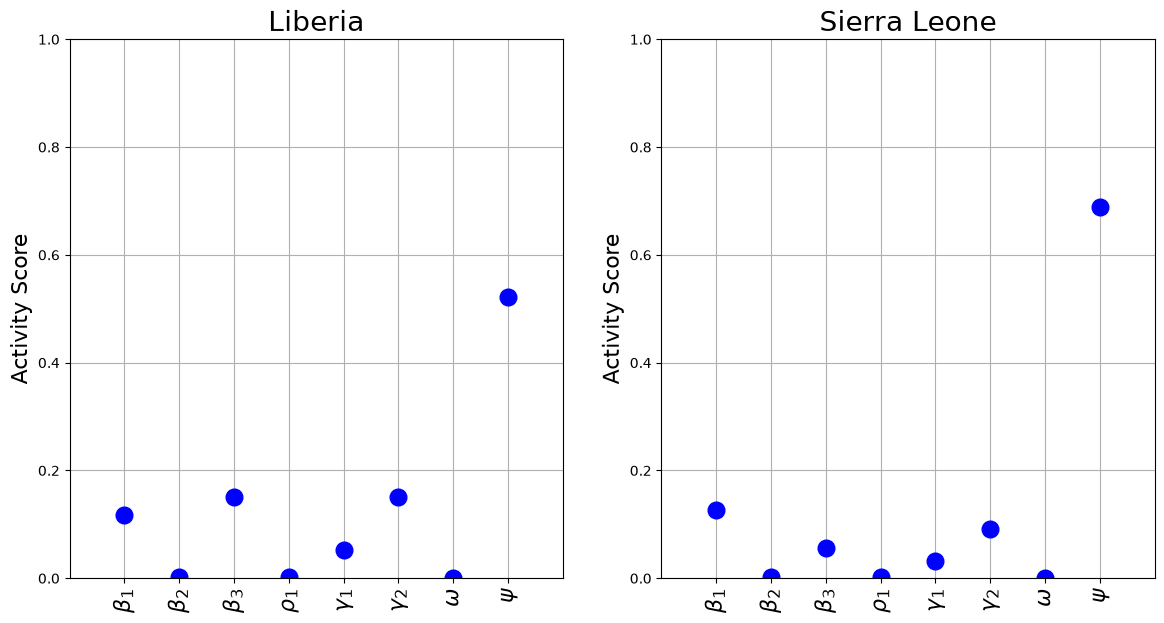

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, c in zip(axes, COUNTRIES):
    alpha = ac.activity_scores(sub[c], n=2)
    alpha = alpha / alpha.sum()
    ax.plot(range(8), alpha, 'bo', markersize=12)
    ax.set_xlim([-1, 8]); ax.set_xticks(range(8), LABELS, rotation='vertical', fontsize=16)
    ax.set_ylim([0, 1]); ax.set_ylabel('Activity Score', fontsize=16)
    ax.set_title(c, fontsize=20)
    ax.grid(True)
    print(f'{c}: normalized activity scores =', ', '.join(f'{n} {v:.3f}' for n, v in zip(NAMES, alpha)))
plt.show()

Again, we see that $\psi$ is vastly more important than the other parameters, and that $\psi$ is more influential on output in Sierra Leone than in Liberia (it has more eigenvector weight and a larger activity score in Sierra Leone: 0.689 against 0.522). Based on these results, it would be reasonable to conclude that additional resources in either country should go towards increasing the hospitalization rate ($\psi$), as it is the most important parameter in each country by a wide margin. The activity scores are global: they average over the whole parameter box. If new resources can change the parameters drastically, they suggest that Sierra Leone would benefit more, as $\psi$ has higher influence in Sierra Leone and thus would more greatly affect $R_0$ there if it were changed. [[1]][R1] (Sections 3 and 5) adds that if resources are scarce and the parameters cannot move far from their current values, its local metrics favor Liberia instead.

In [9]:
print(f'Total runtime {time.perf_counter() - t_start:.0f} s, peak memory {peak_rss_gb()*1e3:.0f} MB')

Total runtime 17 s, peak memory 433 MB
